# 05 — Follow-up evidence, confirmation and interpretation

This notebook validates the recorded v3 experiments and regenerates their analysis; it does not launch optimisation or download data. V1 notebooks remain historical evidence. The 11 November review adds **post-confirmation exploratory** paired budget contrasts and clearer displays of existing controls. It does not retroactively predeclare these analyses.

The primary comparison is at **100 objective calls including 20 common initial points**. CMA's 300-call extension is separate. There are ten battery initial-design groups with three CMA search replicates, and five quadratic groups. All conclusions are conditional on the selected cell, domains, settings and orientations.

The group developed the follow-up diagnostics and interpreted the saved evidence below. Research decisions and member contributions are recorded in `docs/STUDENT_ENGAGEMENT.md`.

In [1]:
from pathlib import Path
import os, json
os.environ.setdefault("MPLBACKEND", "Agg")
import pandas as pd
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/bo_vs_es").exists())
from bo_vs_es.followup_analysis import export_analysis
analysis = export_analysis()
OUT = ROOT / "results/followup_v3"
pd.set_option("display.float_format", lambda x: f"{x:.5g}")
def read(name):
    return pd.read_csv(OUT / f"{name}.csv")
def show(frame, columns=None):
    with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.max_colwidth", None, "display.width", 180):
        display(frame if columns is None else frame[columns])
def picture(name):
    display(Image(filename=str(OUT / f"{name}.png")))
interval_columns = ["estimate", "low", "high", "design_groups"]
show(pd.Series({k: analysis[k] for k in ["analysis_revision", "status", "planned_runs", "complete_runs", "completed_run_search_calls", "assessment_calls"]}).to_frame("value"))
coverage = read("coverage")
show(coverage.groupby("block").agg(design_groups=("initial_design_seed", "nunique"), planned=("planned", "sum"), complete=("complete", "sum"), complete_groups=("complete_group", "sum")).reset_index())
assert analysis["status"] == "complete", "The interpretation below requires the completed frozen grid; inspect coverage before proceeding."
checkpoints = read("checkpoints")
rotations = read("rotation_effects_by_orientation")

/Users/mihirsinha/Downloads/repo/Dsa4212-final-project-bayesian-vs-evolutionary/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


,value
analysis_revision,v3-review-2026-11-11
status,complete
planned_runs,885
complete_runs,885
completed_run_search_calls,196500
assessment_calls,2400


,block,design_groups,planned,complete,complete_groups
0,battery_ball,10,300,300,10
1,battery_boundary,10,360,360,10
2,quadratic_control,5,225,225,5


## Original-history mechanism checks

Corresponding physical histories, queries and acquisition starts separate fitting from acquisition search. These diagnostic starts are not recovered original RNG states. The 80/240-iteration comparison and finite-pool control are distinct interventions; the latter uses 2,048 interior plus 2,048 surface candidates.

The independently fitted predictions agree closely. Increasing the continuous solver cap does not change the selected candidates at these checkpoints. One length-40 replay has distance about 0.81 but a common-model LogEI gap only about 0.0084: distance alone is not acquisition quality. Both pool controls select the same physical candidate at all six checkpoints. This motivates, but does not replace, the sequential check.

,history_seed,observations,component,fitted_prediction_gap,candidate_distance,acquisition_gap
0,0,20,continuous_80,1.7231e-13,1.2063e-06,2.5732e-10
1,0,20,continuous_240,1.7231e-13,1.2063e-06,2.5732e-10
2,0,20,pool_independent_fits,1.7231e-13,0,0
3,0,20,pool_common_fit,1.7231e-13,0,0
4,0,24,continuous_80,3.9968e-15,1.9481e-07,3.7809e-11
5,0,24,continuous_240,3.9968e-15,1.9481e-07,3.7809e-11
6,0,24,pool_independent_fits,3.9968e-15,0,0
7,0,24,pool_common_fit,3.9968e-15,0,0
8,0,40,continuous_80,2.2782e-12,8.6948e-07,3.5014e-10
9,0,40,continuous_240,2.2782e-12,8.6948e-07,3.5014e-10


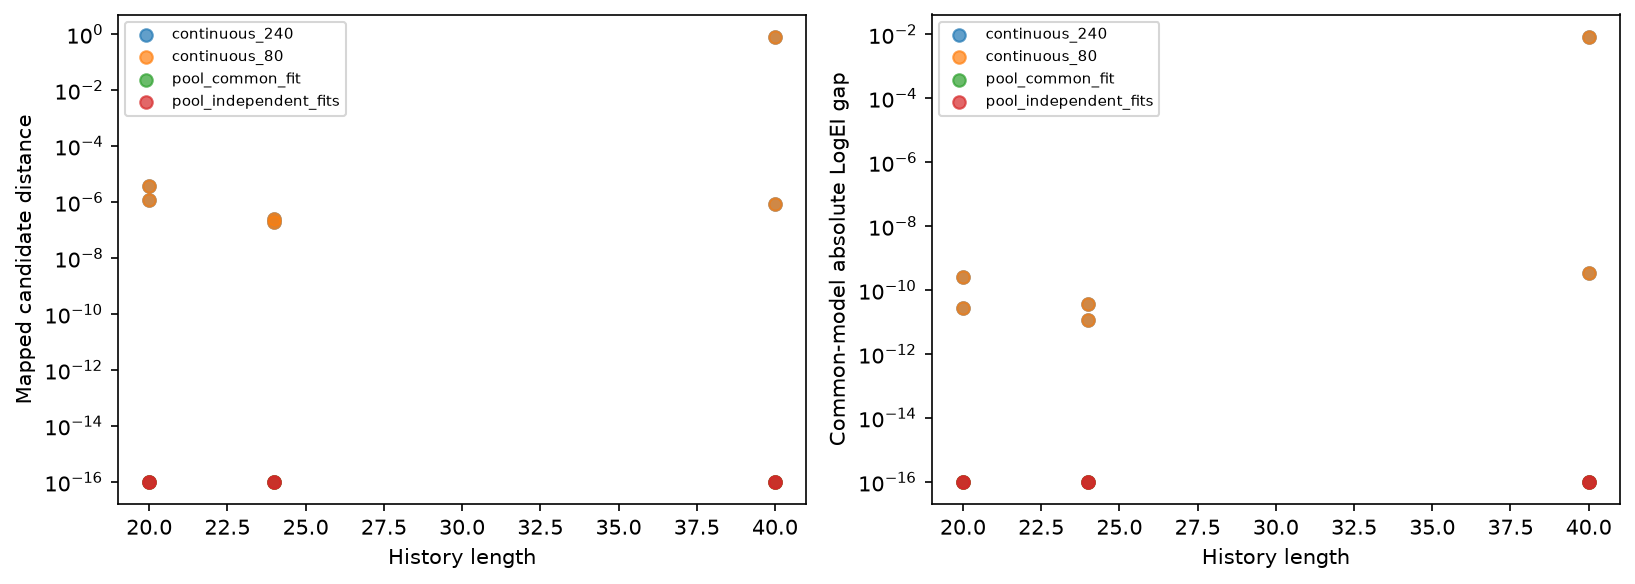

In [2]:
show(read("development_replays"), ["history_seed", "observations", "component", "fitted_prediction_gap", "candidate_distance", "acquisition_gap"])
picture("development_mechanism")

## Sequential pool intervention: matching paths, quality and time

The path plot averages Q202/Q303 within each initial design before taking the median across ten designs. The final-distance table instead describes all 20 paired paths per method; these are not 20 independent designs. The numerical plotting floor is $10^{-16}$.

The pool retains matching paths to floating-point precision, whereas ordinary scalar BO diverges. The quality comparison uses $\log_{10}(L_{\mathrm{pool}}/L_{\mathrm{ordinary}})$; negative values favour the pool. Its 95% percentile intervals resample complete initial designs, separately by orientation. Identity is encoded as -1 in the CSVs.

,method,paired_paths,median_distance,max_distance
0,bo_ard,20,0.98035,1.3263
1,bo_iso,20,0.71879,1.498
2,bo_iso_pool,20,6.8955e-16,1.6746e-15
3,random,20,3.4214e-16,5.9138e-16


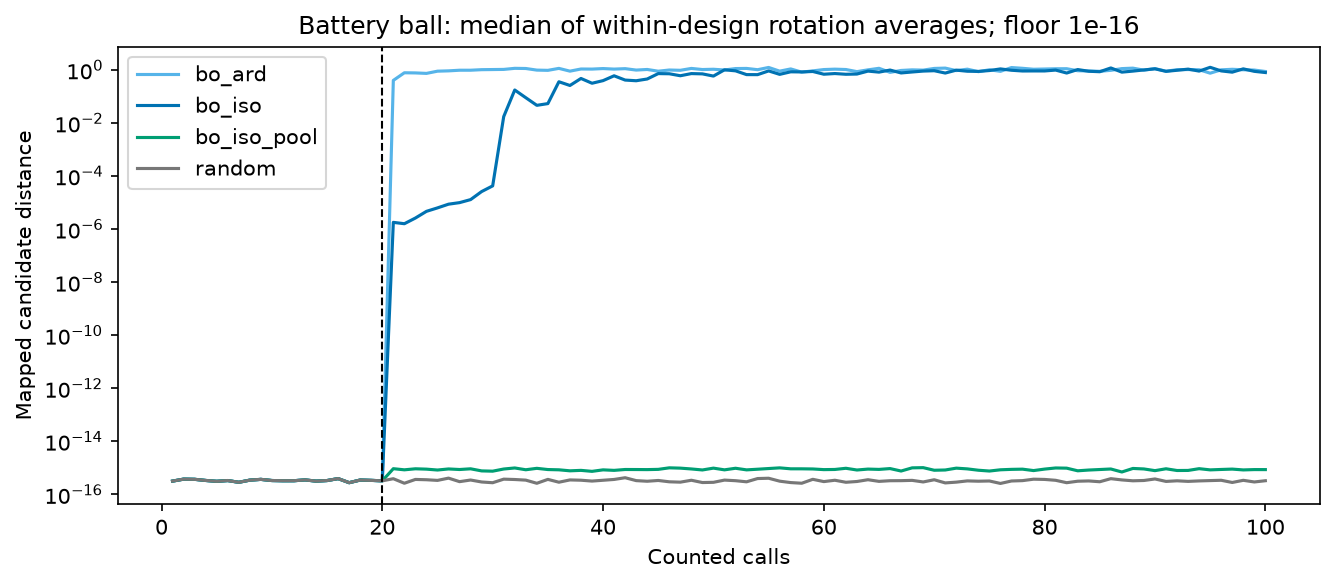

,orientation,estimate,low,high,design_groups
0,-1,-0.075041,-0.24912,0.081206,10
1,202,-0.096972,-0.23908,0.046773,10
2,303,-0.12271,-0.28985,0.01228,10


,method,runs,design_groups,median_rmse_v,median_search_s,median_objective_s,median_overhead_s
0,bo_ard,30,10,0.0060948,25.384,0.14223,25.242
1,bo_iso,30,10,0.006826,21.342,0.14243,21.198
2,bo_iso_pool,30,10,0.0061593,2.3619,0.13998,2.2226
3,cma_diag,90,10,0.010765,0.16036,0.13978,0.020859
4,cma_full,90,10,0.0098132,0.16219,0.13991,0.021854
5,random,30,10,0.012964,0.15117,0.13823,0.012956


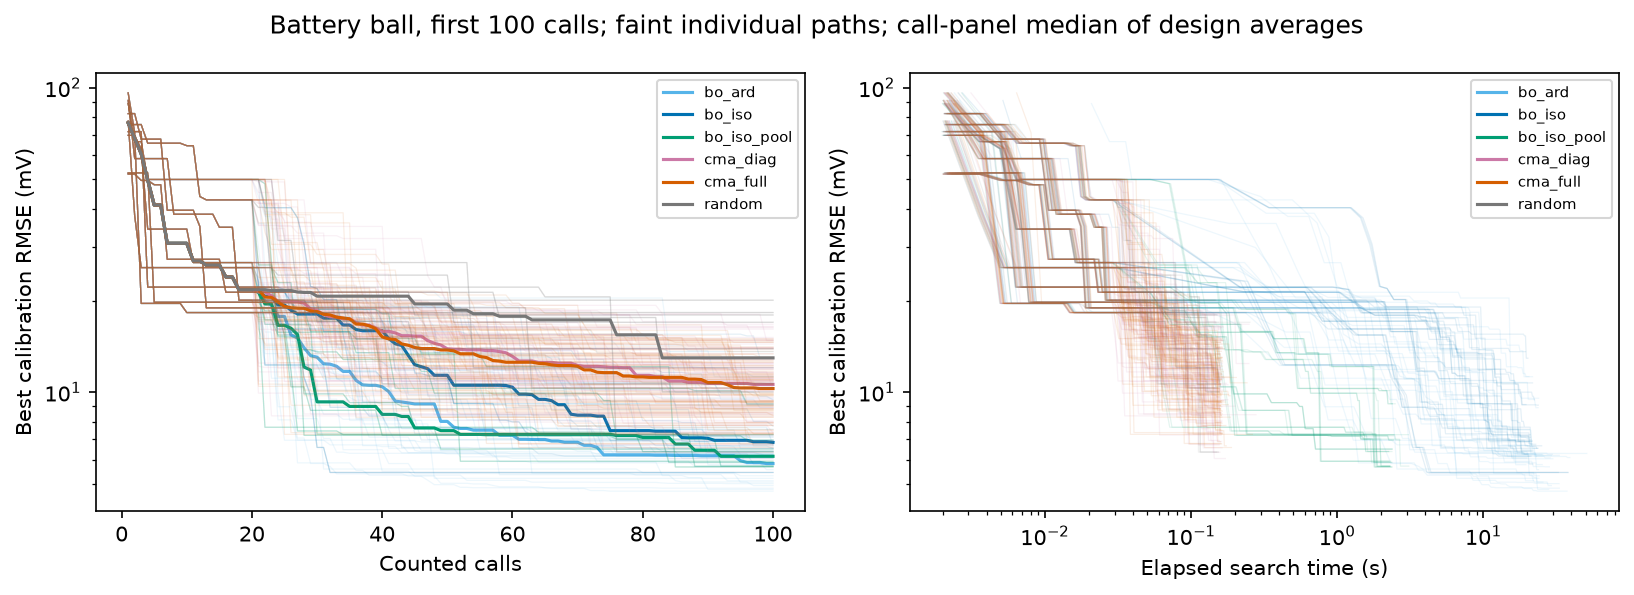

In [3]:
show(read("final_path_summary"))
picture("sequential_path_matching")
show(read("intervention_loss_intervals"), ["orientation", *interval_columns])
show(read("primary_quality_and_timing"))
picture("confirmation_quality_and_time")

The final pool path distances have median $6.90\times10^{-16}$ and maximum $1.67\times10^{-15}$; the ordinary scalar median is about 0.719. Every orientation-specific pool-versus-ordinary loss interval includes zero: **better quality is not established, and equivalence is not established either**.

Descriptive median search time is 2.362 s for the pool versus 21.342 s for ordinary scalar BO; objective time is about 0.14 s for both. Search time includes objective calls and decision/logging overhead. The timing/quality table pools runs and orientations descriptively, not as independent inference units. This is a large implementation-cost reduction on this machine, not an equal-time winner over all algorithms. The pool changes acquisition search, including its candidate set and surface access; it does not identify a unique solver defect or test every acquisition optimiser.

## CMA rotation contrasts beside ordinary search variability

The figure compares **absolute** log-loss differences: each dot is one design's mean over the three search replicates (rotation comparisons), or over the three overlapping independent-search pairs at identity. Black bars are means of the ten design values. Overlapping identity pairs are dependent. These are descriptive magnitudes, not a null distribution, equivalence threshold, or a causal subtraction.

The separate table reports **signed** rotation effects $\log_{10}(L_Q/L_I)$, averaging replicates within designs before bootstrapping ten designs. Positive values mean worse loss after rotation. Similar absolute variability can coexist with a consistent signed mean effect.

,method,calls,orientation,estimate,low,high,design_groups
6,cma_diag,100,202,-0.045268,-0.13025,0.051883,10
7,cma_diag,100,303,0.041007,-0.065157,0.14626,10
8,cma_diag,300,202,0.06543,0.011863,0.11916,10
9,cma_diag,300,303,0.088395,0.030078,0.14241,10
10,cma_full,100,202,0.031735,-0.061345,0.13176,10
11,cma_full,100,303,0.018092,-0.068476,0.11052,10
12,cma_full,300,202,-0.016536,-0.047439,0.013676,10
13,cma_full,300,303,-0.022053,-0.078379,0.02757,10


,method,calls,comparison,design_groups,mean_absolute_log10_ratio
0,cma_diag,100,I vs I (independent searches),10,0.21844
1,cma_diag,100,Q202 vs I,10,0.26541
2,cma_diag,100,Q303 vs I,10,0.26228
3,cma_diag,300,I vs I (independent searches),10,0.061461
4,cma_diag,300,Q202 vs I,10,0.11736
5,cma_diag,300,Q303 vs I,10,0.13773
6,cma_full,100,I vs I (independent searches),10,0.21818
7,cma_full,100,Q202 vs I,10,0.19047
8,cma_full,100,Q303 vs I,10,0.21417
9,cma_full,300,I vs I (independent searches),10,0.094882


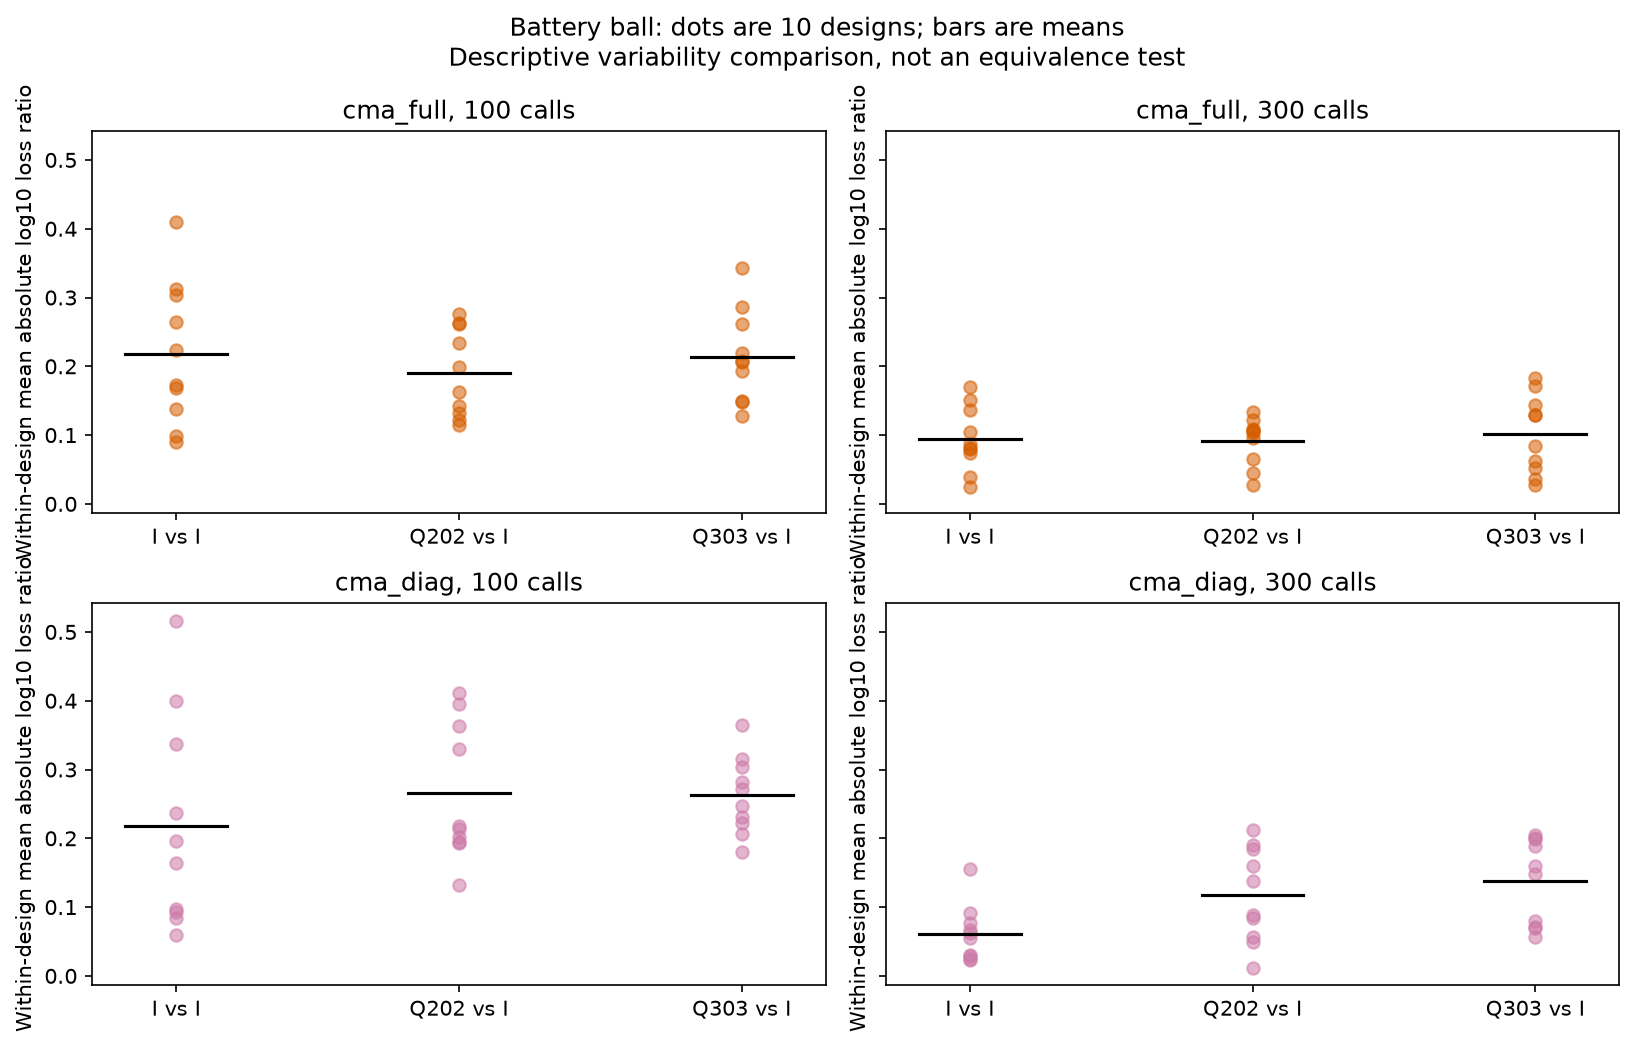

In [4]:
cma_ball = rotations[rotations.block.eq("battery_ball") & rotations.method.str.startswith("cma")]
show(cma_ball, ["method", "calls", "orientation", *interval_columns])
spread = read("cma_variability_summary")
show(spread[spread.block.eq("battery_ball")], ["method", "calls", "comparison", "design_groups", "mean_absolute_log10_ratio"])
picture("cma_rotation_and_variability")

At 100 calls, the signed battery-ball CMA intervals include zero for both orientations and variants. The absolute rotation contrasts have a scale comparable to ordinary search variability, so the absolute contrasts alone do not demonstrate orientation dependence. This does **not** establish no effect or practical equivalence. At 300 calls both diagonal-CMA orientation intervals exclude zero: Q202 has mean log-ratio 0.065 [0.012, 0.119] and Q303 0.088 [0.030, 0.142], approximately 16% and 23% higher geometric-mean MSE than identity. This is evidence of a signed effect for these selected cases, even though ordinary sampling variability remains. Both full-CMA intervals include zero. These intervals are conditional on ten designs and two rotations, not evidence across all rotations.

These are **controlled pycma 4.5.0 variants**: population eight, initial $\sigma=0.3$, isotropic starting covariance, active updates/mirrors/additional diagonal decoding disabled. Diagonal `cc_sep`, `c1_sep`, `cmu_sep` are set to the full variant's constants. Native diagonal and dense update mechanics still differ. Results are not a comparison of all default or optimally tuned CMA implementations.

## What the additional 200 CMA calls establish

Pair each run's checkpoints before aggregation. The interval below is for $\log_{10}(L_{300}/L_{100})$, so negative values mean improved best-observed loss. Replicates are averaged within each design; 95% intervals resample designs. This direct paired summary was added after confirmation.

Checkpoint RMSE medians are descriptive and are shown by orientation. The adaptation plot shows median within-design averages of step size and covariance spectral ratio.

,method,orientation,calls,runs,median_rmse_v
0,cma_diag,-1,100,30,0.010996
1,cma_diag,-1,300,30,0.0062347
2,cma_diag,202,100,30,0.010198
3,cma_diag,202,300,30,0.006376
4,cma_diag,303,100,30,0.011101
5,cma_diag,303,300,30,0.0066427
6,cma_full,-1,100,30,0.0095404
7,cma_full,-1,300,30,0.005959
8,cma_full,202,100,30,0.0097686
9,cma_full,202,300,30,0.0058083


,method,orientation,estimate,low,high,design_groups
0,cma_diag,-1,-0.45897,-0.53906,-0.3732,10
1,cma_diag,202,-0.34828,-0.39925,-0.30235,10
2,cma_diag,303,-0.41158,-0.50075,-0.33131,10
3,cma_full,-1,-0.43874,-0.50884,-0.36105,10
4,cma_full,202,-0.48701,-0.55758,-0.40807,10
5,cma_full,303,-0.47888,-0.54652,-0.4178,10


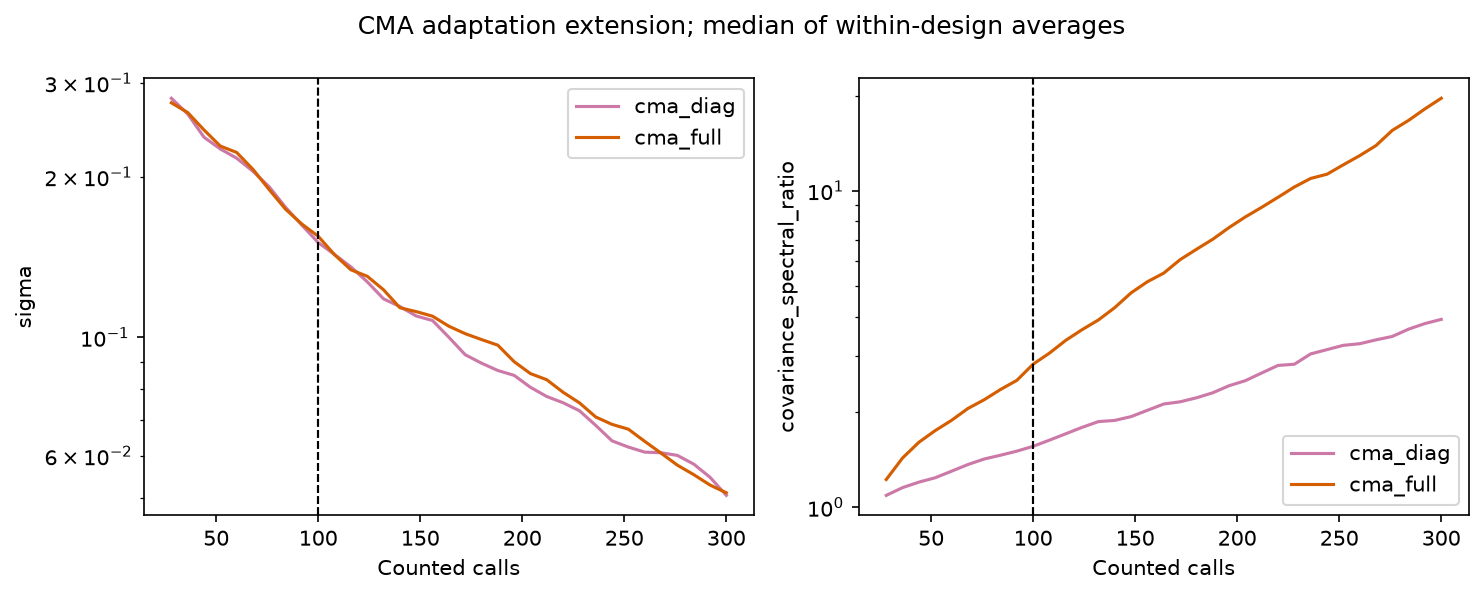

In [5]:
quality = read("cma_checkpoint_quality")
show(quality[quality.block.eq("battery_ball")], ["method", "orientation", "calls", "runs", "median_rmse_v"])
change = read("cma_budget_change_intervals")
show(change[change.block.eq("battery_ball")], ["method", "orientation", *interval_columns])
picture("cma_adaptation")

Across the battery-ball runs and orientations, median RMSE decreases from approximately 9.81 to 5.95 mV for full CMA and 10.76 to 6.37 mV for diagonal CMA. More evaluations allow better solutions while step size decreases and the covariance becomes more anisotropic.

**This does not show covariance alignment with useful objective directions, or that covariance adaptation caused the improvement.** More evaluations and step-size adaptation also change the search; a covariance spectral ratio contains no directional information. No alignment statistic or covariance-update ablation is supplied by these summaries. The 300-call extension is a within-CMA analysis, not an equal-budget comparison with 100-call BO.

## Boundary handling: same physical box, paired budget change

For each method/design/search replicate/orientation, define $B_n=[\log_{10}(L_Q/L_I)]_{\mathrm{project},n}-[\log_{10}(L_Q/L_I)]_{\mathrm{resample},n}$. The first table gives $B_{100}$ and $B_{300}$ separately. The second directly estimates **$B_{300}-B_{100}$**, pairing within the same runs before averaging replicates and bootstrapping ten designs. This second contrast is **post-confirmation exploratory**, not a predeclared confirmation test.

Changing whether two separate intervals include zero is not a test of the budget difference. The descriptive figure averages both orientations and replicates within a design; the interaction tables retain orientations. The exposure table pools orientations/replicates descriptively and is not an inferential comparison.

,method,calls,orientation,estimate,low,high,design_groups
0,cma_diag,100,202,0.18663,0.08782,0.28461,10
1,cma_diag,100,303,0.12394,0.0074399,0.2393,10
2,cma_diag,300,202,0.0047245,-0.089147,0.094676,10
3,cma_diag,300,303,0.037046,-0.067359,0.16472,10
4,cma_full,100,202,-0.010042,-0.10798,0.068275,10
5,cma_full,100,303,-0.065053,-0.16378,0.023817,10
6,cma_full,300,202,-0.0096442,-0.084067,0.0655,10
7,cma_full,300,303,0.026799,-0.084231,0.14883,10


,method,orientation,estimate,low,high,design_groups
0,cma_diag,202,-0.18191,-0.25492,-0.11639,10
1,cma_diag,303,-0.086892,-0.20185,0.015639,10
2,cma_full,202,0.00039761,-0.12666,0.15612,10
3,cma_full,303,0.091852,-0.084911,0.28399,10


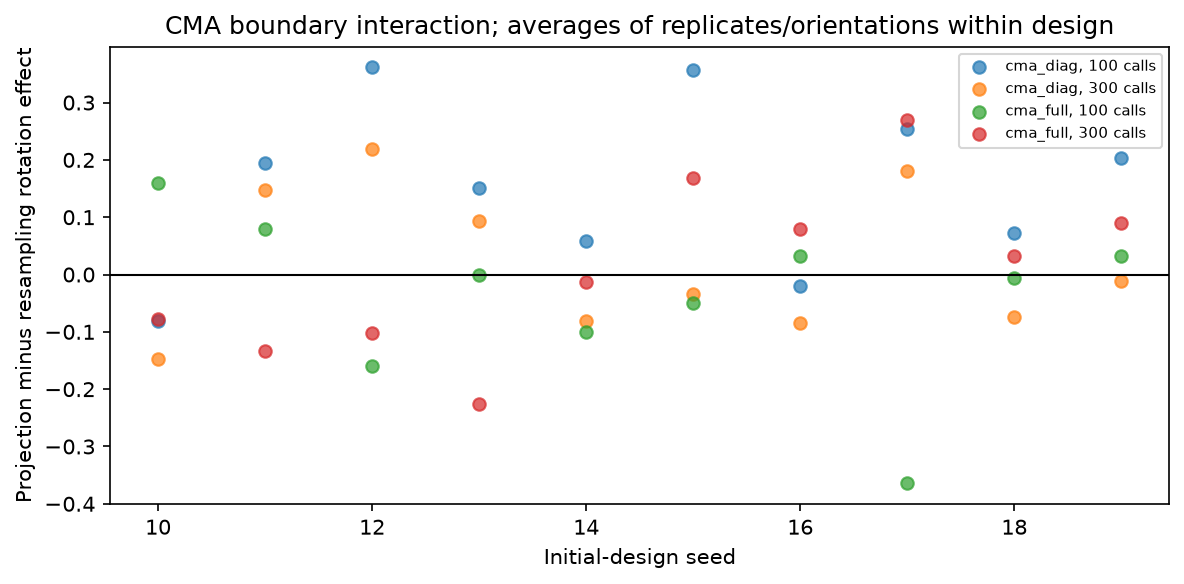

,method,handler,calls,mean_rejected_fraction,mean_repaired_fraction,mean_boundary_fraction
0,cma_diag,project,100,0,0.21708,0.17367
1,cma_diag,project,300,0,0.1,0.093333
2,cma_diag,resample,100,0.17336,0,0
3,cma_diag,resample,300,0.075753,0,0
4,cma_full,project,100,0,0.17625,0.141
5,cma_full,project,300,0,0.08246,0.076963
6,cma_full,resample,100,0.16373,0,0
7,cma_full,resample,300,0.067571,0,0


In [6]:
show(read("boundary_interaction_intervals"), ["method", "calls", "orientation", *interval_columns])
show(read("boundary_budget_change_intervals"), ["method", "orientation", *interval_columns])
picture("boundary_interactions")
boundary = checkpoints[checkpoints.block.eq("battery_boundary")]
show(boundary.groupby(["method", "handler", "calls"]).agg(mean_rejected_fraction=("rejected_fraction", "mean"), mean_repaired_fraction=("repaired_fraction", "mean"), mean_boundary_fraction=("evaluated_boundary_fraction", "mean")).reset_index())

Diagonal CMA's interaction attenuates from 0.187 to 0.005 under Q202 and from 0.124 to 0.037 under Q303. The paired budget-change estimate is **-0.182, interval [-0.255, -0.116]** for Q202, and **-0.087, interval [-0.202, 0.016]** for Q303. Evidence for attenuation is stronger for Q202. The 300-call intervals including zero do not prove the interaction disappeared. Both full-CMA budget-change intervals include zero.

This is a **CMA boundary-handler interaction on the same physical box**. Both implemented handlers respect the coordinate transformation. It is not a percentage of BO/CMA sensitivity attributable to boundaries, nor a BO boundary intervention. Boundary occupancy and rejection/repair rates describe exposure; they do not independently establish the causal mechanism.

## Conditioning controls and numerical assumptions

Each comparison below rotates the same quadratic and preserves its condition number. There are only **five design groups** per condition; intervals are exploratory and conditional on two chosen rotations. A large rotated/identity ratio does not by itself establish a worse absolute score than another method.

The plot shows means without uncertainty bars; the focused tables supply orientation-specific intervals and absolute final losses. The health table counts fits with **any** length scale within 1% of its upper bound, not individual length-scale entries.

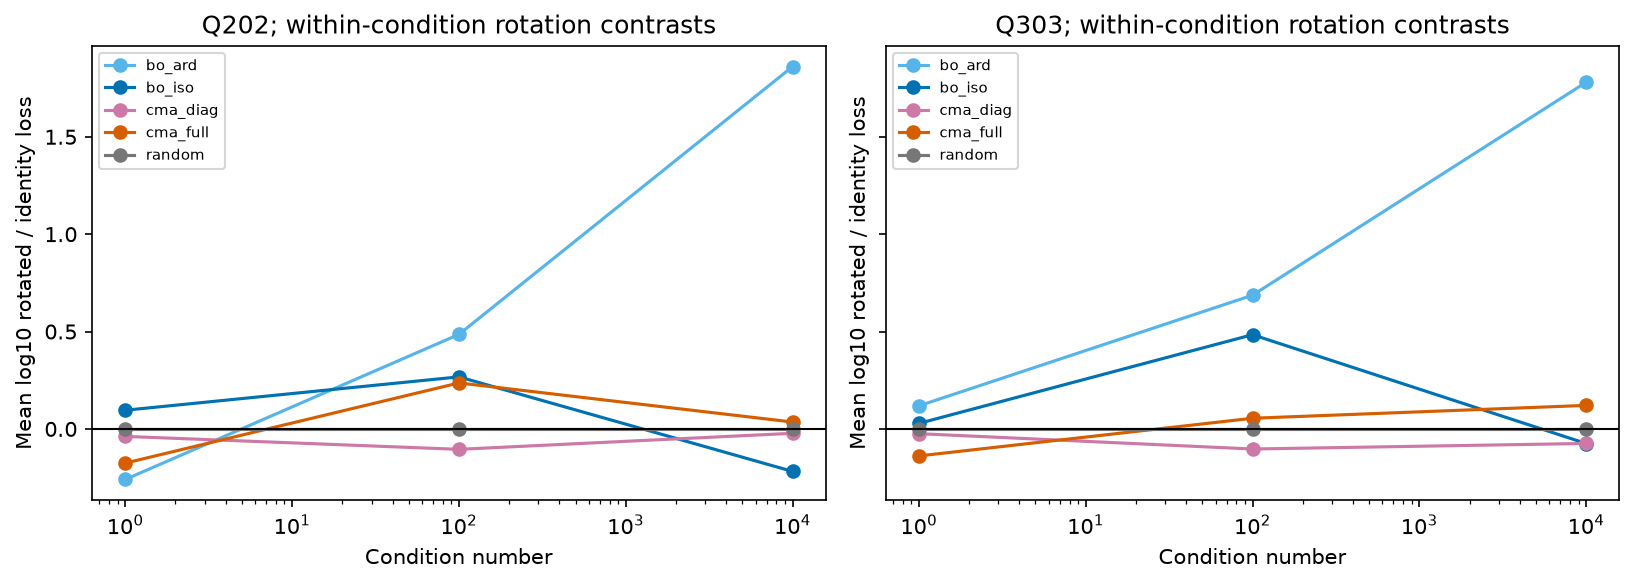

,condition,method,orientation,estimate,low,high,design_groups
32,1,bo_ard,202,-0.25936,-0.55837,-0.037619,5
33,1,bo_ard,303,0.11863,-0.052912,0.29017,5
34,1,bo_iso,202,0.096006,-0.0033256,0.23172,5
35,1,bo_iso,303,0.028463,-0.057194,0.15009,5
42,100,bo_ard,202,0.48525,0.2321,0.76023,5
43,100,bo_ard,303,0.68648,0.36093,0.92566,5
44,100,bo_iso,202,0.26728,-0.053713,0.58628,5
45,100,bo_iso,303,0.48384,0.27171,0.67923,5
52,10000,bo_ard,202,1.8603,1.5951,2.1524,5
53,10000,bo_ard,303,1.7801,1.6265,1.9348,5


orientation              -1          202        303
condition method                                   
1         bo_ard   1.5592e-06 8.8588e-07 1.7752e-06
          bo_iso   1.0848e-06 1.8279e-06 1.4814e-06
          cma_diag   0.005014  0.0041529   0.006075
          cma_full  0.0040834  0.0011289  0.0024754
          random     0.041074   0.041074   0.041074
100       bo_ard   1.1634e-06 3.9951e-06  6.063e-06
          bo_iso   3.5412e-06 1.4474e-05 1.5036e-05
          cma_diag  0.0040989  0.0027458  0.0047351
          cma_full    0.00114   0.002102  0.0014134
          random     0.011048   0.011048   0.011048
10000     bo_ard   1.7892e-06  0.0001669 0.00012126
          bo_iso   0.00014027 8.6624e-05 0.00014316
          cma_diag 0.00094419 0.00067346 0.00069116
          cma_full 0.00063833 0.00090424 0.00070789
          random    0.0024322  0.0024322  0.0024322

,block,method,fits,near_upper,near_lower,warnings
0,battery_ball,bo_ard,2400,1009,1,0
1,battery_ball,bo_iso,2400,0,0,0
2,battery_ball,bo_iso_pool,2400,0,0,0
3,quadratic_control,bo_ard,3600,3256,0,0
4,quadratic_control,bo_iso,3600,1271,0,0


,method,fit_status,fits
0,bo_ard,OptimizationStatus.STOPPED,29
1,bo_ard,OptimizationStatus.SUCCESS,5971
2,bo_iso,OptimizationStatus.SUCCESS,6000
3,bo_iso_pool,OptimizationStatus.SUCCESS,2400


In [7]:
picture("quadratic_rotation_contrasts")
show(rotations[rotations.block.eq("quadratic_control") & rotations.method.isin(["bo_ard", "bo_iso"])], ["condition", "method", "orientation", *interval_columns])
q = checkpoints[checkpoints.block.eq("quadratic_control")]
show(q.pivot_table(index=["condition", "method"], columns="orientation", values="loss", aggfunc="median"))
health = read("optimiser_health")
show(health.groupby(["block", "method"]).agg(fits=("fit_status", "size"), near_upper=("near_upper_bound", "sum"), near_lower=("near_lower_bound", "sum"), warnings=("warnings", "sum")).reset_index())
show(health.groupby(["method", "fit_status"]).size().rename("fits").reset_index())

At $\kappa=10^4$, ARD's geometric-mean rotated/identity loss ratios are about **72.5 for Q202 and 60.3 for Q303**. This supports substantial orientation dependence for this configured ARD pipeline. It does not isolate representation from fitting bounds and acquisition numerics: 4,265/6,000 ARD fits approach the upper length-scale bound (1,009/2,400 battery fits; 3,256/3,600 quadratic fits), and 29 ARD fits have STOPPED status. V3 has no pool-ARD control or bound intervention. Full/diagonal CMA do not establish a universal rotation-sensitivity ordering on these short quadratic runs.

## Targets and predictive assessment

Targets were set from development evidence. Hit rates include non-attainment; times/calls are conditional on reaching the target. The table retains orientation and the common 100-call budget. CMA has 30 runs per orientation versus ten for each BO/random variant, arising from three searches per design, not extra independent designs. FUDS assessments occur after all search and never feed back into optimisation; previously inspected FUDS is not untouched validation of later modelling choices.

In [8]:
targets = read("target_summary")
show(targets[targets.block.eq("battery_ball") & targets.calls.eq(100)], ["method", "orientation", "target_rmse_v", "runs", "hits", "hit_rate", "median_calls_if_reached", "median_seconds_if_reached"])
primary = checkpoints[checkpoints.block.eq("battery_ball") & checkpoints.calls.eq(100)]
show(primary.groupby("method")[["fuds80_rmse_v", "fuds50_rmse_v"]].median().rename(columns=lambda c: "median_" + c).reset_index())

,method,orientation,target_rmse_v,runs,hits,hit_rate,median_calls_if_reached,median_seconds_if_reached
0,bo_ard,-1,0.006,10,4,0.4,49.5,7.993
1,bo_ard,-1,0.01,10,10,1,36.5,4.0273
2,bo_ard,202,0.006,10,3,0.3,48,6.5654
3,bo_ard,202,0.01,10,8,0.8,45.5,6.0299
4,bo_ard,303,0.006,10,6,0.6,68,13.999
5,bo_ard,303,0.01,10,10,1,43,5.5733
6,bo_iso,-1,0.006,10,2,0.2,64.5,12.355
7,bo_iso,-1,0.01,10,9,0.9,56,9.4626
8,bo_iso,202,0.006,10,1,0.1,32,4.3853
9,bo_iso,202,0.01,10,9,0.9,47,7.3102


,method,median_fuds80_rmse_v,median_fuds50_rmse_v
0,bo_ard,0.0072908,0.0062313
1,bo_iso,0.0077798,0.007264
2,bo_iso_pool,0.0074654,0.0068459
3,cma_diag,0.0097724,0.010298
4,cma_full,0.0088464,0.0099788
5,random,0.011388,0.011933


## Feasible reference and local geometry

The reference is a computed feasible point, not a certified optimum or identical-information competitor. Ambient finite-difference perturbations can leave the ball and are separately counted. This spectrum is not global conditioning or constrained tangent curvature.

In [9]:
if (OUT / "ball_reference.json").exists():
    reference = json.loads((OUT / "ball_reference.json").read_text())
    display(pd.Series(reference["reference"]))
    display(pd.DataFrame(reference["terminations"]))
    display(pd.Series(reference["assessments"]))
    print("Local eigenvalues:", reference["eigenvalues"])
    print("Extra diagnostic/assessment calls:", reference["extra_simulator_calls"])
    pilot = pd.read_csv(ROOT / "results/tables/pilot_runs.csv")
    best = pilot[pilot.block.eq("battery_ball")].sort_values("best_loss").iloc[0]
    print("Best pilot ball loss:", best.best_loss, "source:", best.run_id)
    print("A worse computed reference does not invalidate the better feasible pilot observation.")

evaluation                                                 1170
u             [0.640941, 0.245439, 0.135491, 0.570485, 0.430...
feasible                                                   True
norm                                                          1
status                                                       ok
loss                                                 3.4843e-05
dtype: object

,start,success,message,iterations,solver_final_norm,termination
0,0,True,Optimization terminated successfully,33,1,solver
1,1,False,Counted simulator-call allocation reached,NaN,NaN,budget
2,2,False,Counted simulator-call allocation reached,NaN,NaN,budget


fuds80_rmse_v   0.0076271
fuds50_rmse_v    0.006018
dtype: float64

Local eigenvalues: [8.922526266662363e-07, 7.220246305740753e-05, 0.0006522046810147618, 0.009495004786377938, 0.10075283006652214]
Extra diagnostic/assessment calls: 12
Best pilot ball loss: 2.2415188969724052e-05 source: fe779a2fc258100f
A worse computed reference does not invalidate the better feasible pilot observation.


## Supported conclusions and remaining uncertainty

- The mapped finite pool preserves scalar-BO paths in these runs and greatly reduces search overhead. Its loss intervals do not establish a quality improvement or equivalence.
- ARD has substantial rotation dependence on the highly conditioned quadratics. Diagonal-metric representation, active length-scale bounds and numerical search are not yet separated.
- CMA rotation contrasts must be interpreted alongside ordinary search variability. Extra calls improve loss and change covariance shape, but directional alignment and causal benefit of covariance adaptation are not demonstrated.
- The same-box diagonal-CMA boundary interaction attenuates, with stronger paired evidence under Q202. Absence at 300 calls is not established, and no universal boundary-attributable percentage is estimated.
- Evidence is conditional on one cell, a 3,600 s window, transferred OCV, fixed capacity/SOC, selected domains/rotations and controlled algorithm settings. Additional search seeds do not supply independent batteries.

The paired budget analyses and presentation summaries were added after confirmation and are exploratory. The recorded optimisation trajectories, budgets and original hypotheses have not changed. Exact source run IDs remain in the exported detailed tables, and `validation.json` hashes the regenerated outputs. Students should verify these interpretations, not substitute the notebook's attribution for their own engagement. The optional V4 proposal review is in `docs/V4_SCOPE_REVIEW.md`; no V4 experiment is launched here.